Датасет:

https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

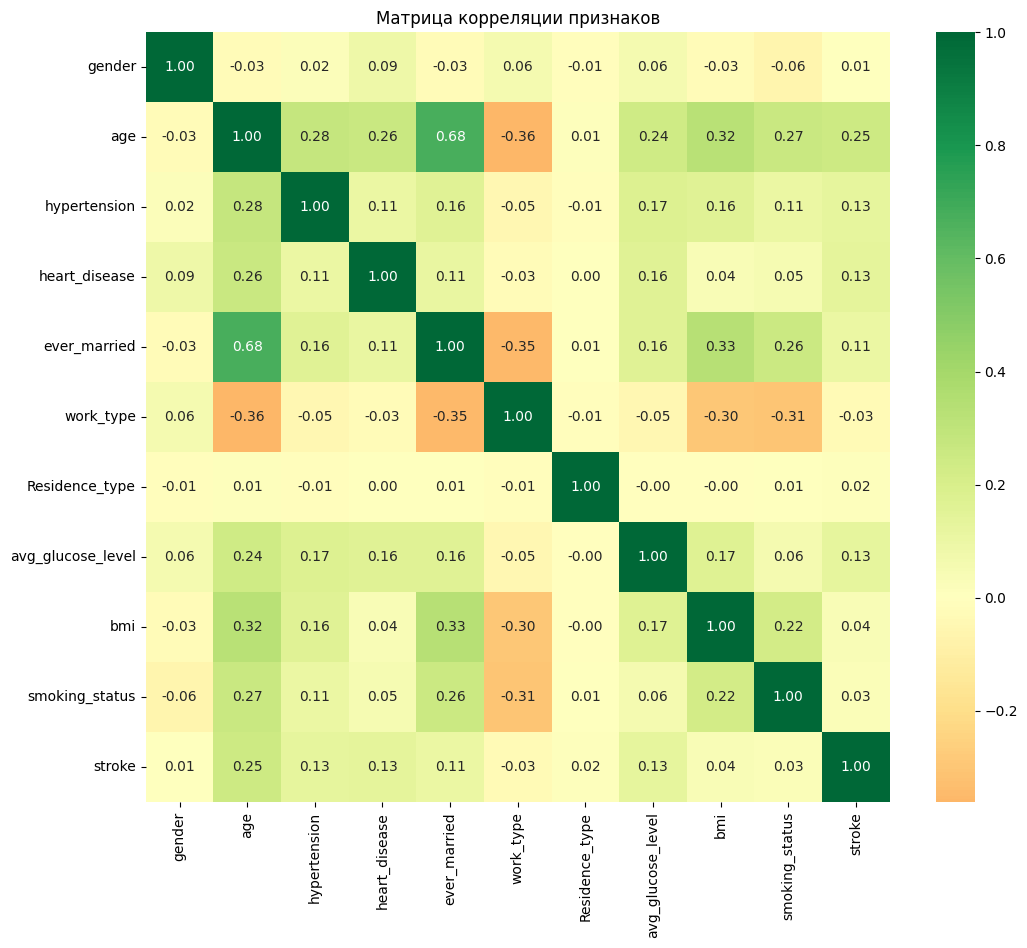

stroke               1.000000
age                  0.245257
heart_disease        0.134914
avg_glucose_level    0.131945
hypertension         0.127904
ever_married         0.108340
bmi                  0.036110
smoking_status       0.028123
Residence_type       0.015458
gender               0.008929
work_type           -0.032316
Name: stroke, dtype: float64


In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("healthcare-dataset-stroke-data.csv")

df = df.drop(columns=["id"])

df["bmi"] = df["bmi"].fillna(df["bmi"].median())
df["smoking_status"] = df["smoking_status"].fillna("unknown")

cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]


for col in cat_cols:
    df[col] = LabelEncoder().fit_transform(df[col])
    
    
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Матрица корреляции признаков")
plt.show()

corr = df.corr()["stroke"].sort_values(ascending=False)
print(corr)



Точность на обучении: 0.76
Точность на тесте: 0.77
               precision    recall  f1-score   support

no stroke (0)       0.97      0.78      0.86       960
   stroke (1)       0.16      0.66      0.26        62

     accuracy                           0.77      1022
    macro avg       0.57      0.72      0.56      1022
 weighted avg       0.92      0.77      0.83      1022



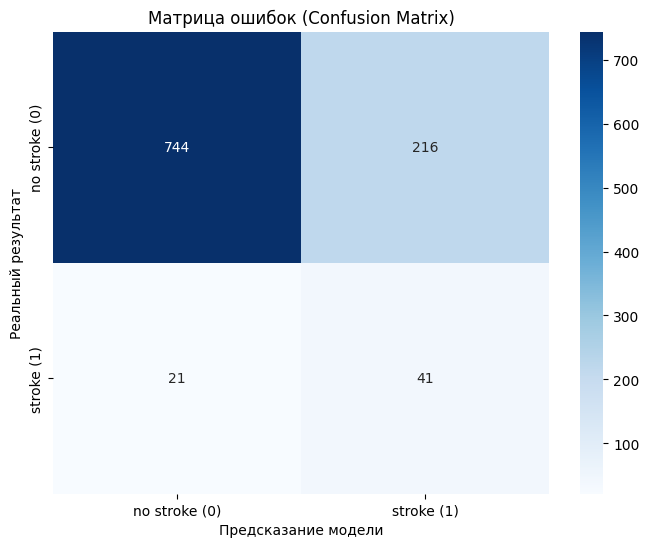

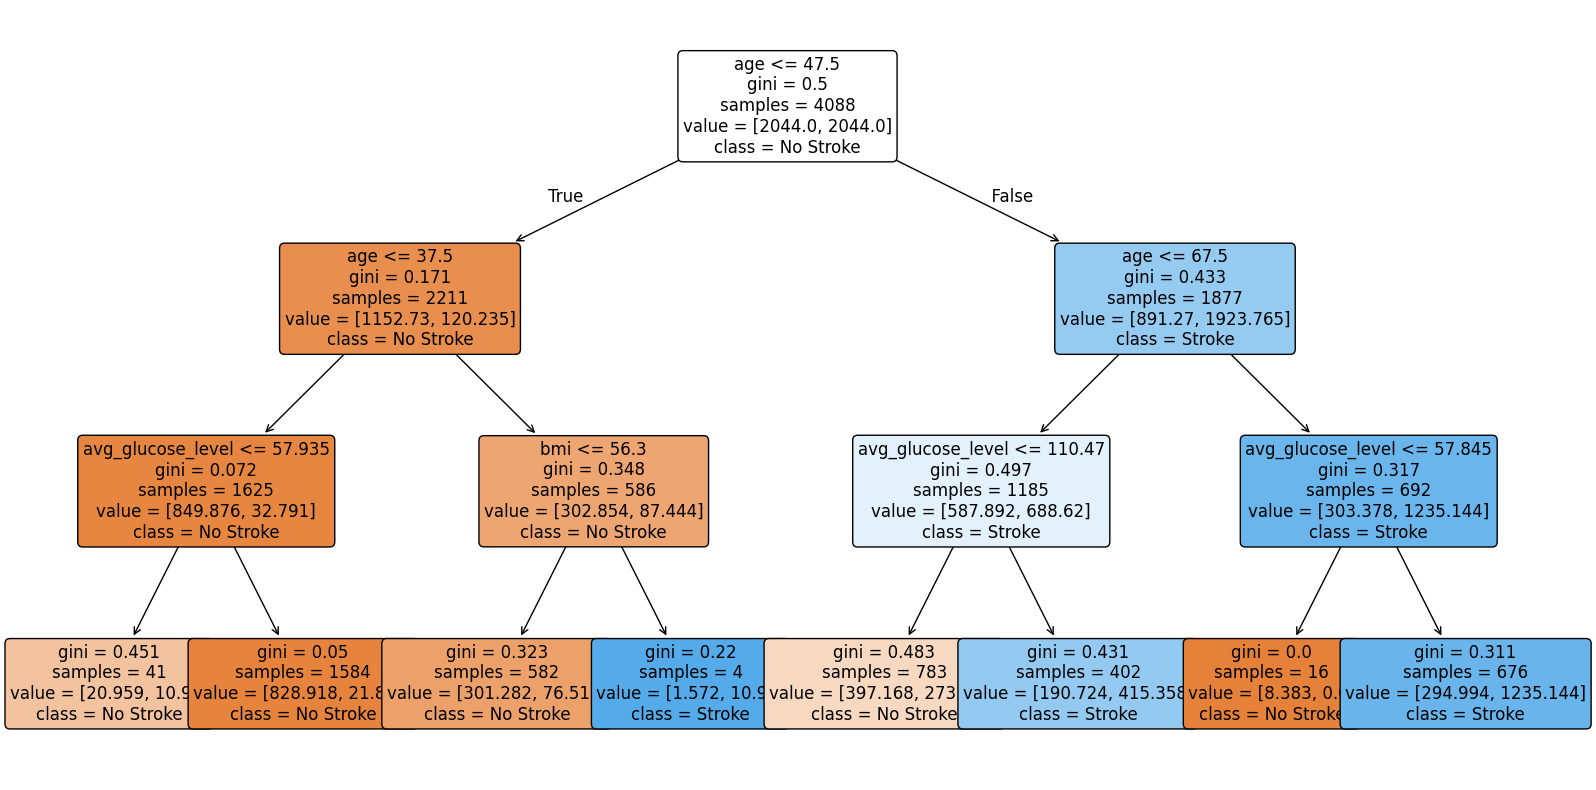

In [2]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier, plot_tree

seed = 42

X = df.drop(["stroke", "work_type"], axis=1)
y = df["stroke"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
tree_model = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=seed, ccp_alpha=0.0)
tree_model.fit(X_train, y_train)

train_score = tree_model.score(X_train, y_train)
test_score = tree_model.score(X_test, y_test)

print(f"Точность на обучении: {train_score:.2f}")
print(f"Точность на тесте: {test_score:.2f}")

text_labels = ["no stroke (0)", "stroke (1)"]

y_pred = tree_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=text_labels))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=text_labels,  
    yticklabels=text_labels, 
)
plt.xlabel("Предсказание модели")
plt.ylabel("Реальный результат")
plt.title("Матрица ошибок (Confusion Matrix)")
plt.show()

plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=list(X.columns),
    class_names=["No Stroke", "Stroke"], 
    filled=True,
    rounded=True,
    fontsize=12,
)
plt.show()

In [3]:
import numpy as np

term_boundaries = {}
for col in X_train.columns:
    values = X_train[col]
    unique_vals = sorted(values.unique())

    if type(values.tolist()[0]) is bool or unique_vals == [0, 1]:
        term_boundaries[col] = (0, 1)
    else:
        q33 = values.quantile(0.33)
        q66 = values.quantile(0.66)
        term_boundaries[col] = (q33, q66)
        
print(term_boundaries)

{'gender': (0, 1), 'age': (np.float64(32.0), np.float64(55.0)), 'hypertension': (0, 1), 'heart_disease': (0, 1), 'ever_married': (0, 1), 'Residence_type': (0, 1), 'avg_glucose_level': (np.float64(81.7542), np.float64(104.36)), 'bmi': (np.float64(25.3), np.float64(30.7)), 'smoking_status': (np.float64(1.0), np.float64(2.0))}


In [13]:
def value_to_term(col: str, value: float, direction: str) -> str:
    low, high = term_boundaries[col]
    if direction == "<=":
        if value <= low:
            return "низкий"
        elif value <= high:
            return "средний"
        else:
            return "высокий"
    elif value > high:
        return "высокий"
    elif value > low:
        return "средний"
    else:
        return "низкий"
    
rules = []


def recurse(node: int, conditions: list) -> None:
    if children_left[node] == -1 and children_right[node] == -1: 
        class_idx = np.argmax(values[node][0])
        rule = {"conditions": conditions, "class": class_idx, "samples": tree.n_node_samples[node]}
        rules.append(rule)
    else:
        cond_left = conditions.copy()
        feat = feature[node]
        feat_name = X_train.columns[feat]
        thr = threshold[node]
        term_left = value_to_term(feat_name, thr, "<=")
        cond_left.append((feat_name, term_left))
        recurse(children_left[node], cond_left)

        cond_right = conditions.copy()
        term_right = value_to_term(feat_name, thr, ">")
        cond_right.append((feat_name, term_right))
        recurse(children_right[node], cond_right)


tree = tree_model.tree_
children_left = tree.children_left
children_right = tree.children_right
feature = tree.feature
threshold = tree.threshold
values = tree.value

print(tree)

recurse(0, [])

    
'''for i, r in enumerate(rules):
    ante = " И ".join([f"{feat} = {term}" for feat, term in r["conditions"]])
    print(f"Правило {i + 1}: ЕСЛИ {ante} ТО класс = {r['class']} (вес = {r['samples']})")'''


'for i, r in enumerate(rules):\n    ante = " И ".join([f"{feat} = {term}" for feat, term in r["conditions"]])\n    print(f"Правило {i + 1}: ЕСЛИ {ante} ТО класс = {r[\'class\']} (вес = {r[\'samples\']})")'

In [5]:
age_min, age_q1, age_q2, age_q3, age_max = df["age"].quantile([0, 0.25, 0.5, 0.75, 1])
print("Стage:")
print(f"  Минимум: {age_min}")
print(f"  1-й квартиль (25%): {age_q1}")
print(f"  Медиана (50%): {age_q2}")
print(f"  3-й квартиль (75%): {age_q3}")
print(f"  Максимум: {age_max}")

glucose_min, glucose_q1, glucose_q2, glucose_q3, glucose_max = df["avg_glucose_level"].quantile([0, 0.25, 0.5, 0.75, 1])
print("\navg_glucose_level:")
print(f"  Минимум: {glucose_min}")
print(f"  1-й квартиль (25%): {glucose_q1}")
print(f"  Медиана (50%): {glucose_q2}")
print(f"  3-й квартиль (75%): {glucose_q3}")
print(f"  Максимум: {glucose_max}")

bmi_min, bmi_q1, bmi_q2, bmi_q3, bmi_max = df["bmi"].quantile([0, 0.25, 0.5, 0.75, 1])
print("\nbmi:")
print(f"  Минимум: {bmi_min}")
print(f"  1-й квартиль (25%): {bmi_q1}")
print(f"  Медиана (50%): {bmi_q2}")
print(f"  3-й квартиль (75%): {bmi_q3}")
print(f"  Максимум: {bmi_max}")



Стage:
  Минимум: 0.08
  1-й квартиль (25%): 25.0
  Медиана (50%): 45.0
  3-й квартиль (75%): 61.0
  Максимум: 82.0

avg_glucose_level:
  Минимум: 55.12
  1-й квартиль (25%): 77.245
  Медиана (50%): 91.88499999999999
  3-й квартиль (75%): 114.09
  Максимум: 271.74

bmi:
  Минимум: 10.3
  1-й квартиль (25%): 23.8
  Медиана (50%): 28.1
  3-й квартиль (75%): 32.8
  Максимум: 97.6


c:\Users\Anita\AppData\Local\Programs\Python\Python313\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


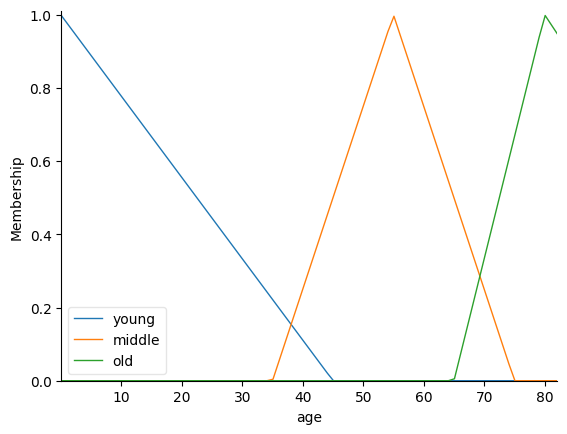

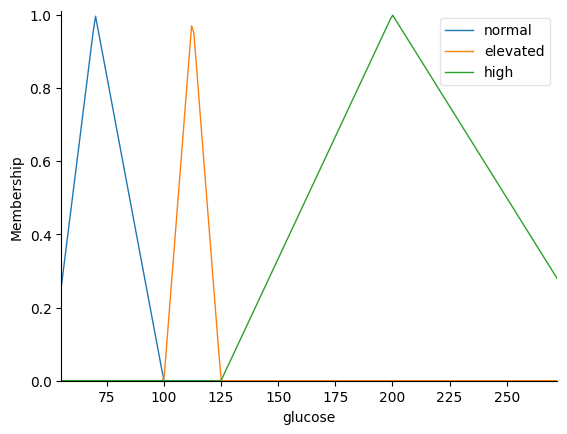

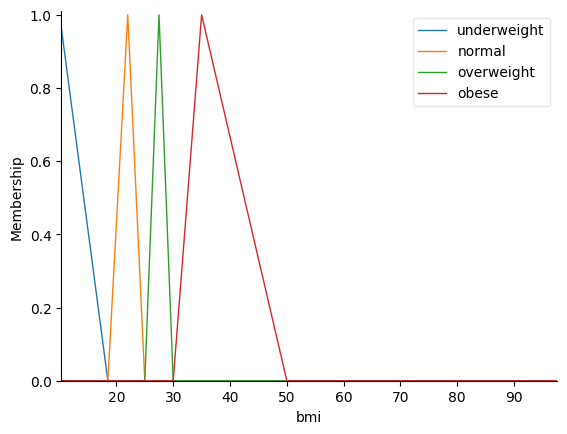

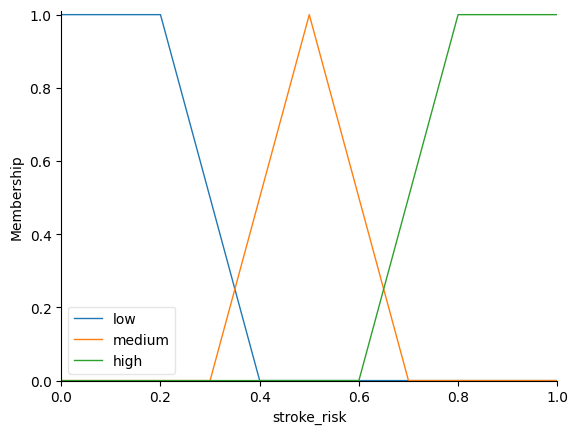

In [6]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

age = ctrl.Antecedent(np.arange(age_min, age_max + 1, 1), "age")
glucose = ctrl.Antecedent(np.arange(glucose_min, glucose_max + 1, 1), "glucose")
bmi = ctrl.Antecedent(np.arange(bmi_min, bmi_max + 0.1, 0.1), "bmi")
stroke_risk = ctrl.Consequent(np.arange(0, 1.1, 0.1), "stroke_risk")

age["young"] = fuzz.trimf(age.universe, [0, 0, 45])
age["middle"] = fuzz.trimf(age.universe, [35, 55, 75])
age["old"] = fuzz.trimf(age.universe, [65, 80, 120])

glucose["normal"] = fuzz.trimf(glucose.universe, [50, 70, 100])
glucose["elevated"] = fuzz.trimf(glucose.universe, [100, 112.5, 125])
glucose["high"] = fuzz.trimf(glucose.universe, [125, 200, 300])

bmi["underweight"] = fuzz.trimf(bmi.universe, [10, 10, 18.5])
bmi["normal"] = fuzz.trimf(bmi.universe, [18.5, 22, 25])
bmi["overweight"] = fuzz.trimf(bmi.universe, [25, 27.5, 30])
bmi["obese"] = fuzz.trimf(bmi.universe, [30, 35, 50])

stroke_risk["low"] = fuzz.trapmf(stroke_risk.universe, [0, 0, 0.2, 0.4])
stroke_risk["medium"] = fuzz.trimf(stroke_risk.universe, [0.3, 0.5, 0.7])
stroke_risk["high"] = fuzz.trapmf(stroke_risk.universe, [0.6, 0.8, 1, 1])

rules = [
    ctrl.Rule(age["young"] & glucose["normal"] & bmi["normal"], stroke_risk["low"]),
    ctrl.Rule(age["young"] & glucose["normal"] & bmi["underweight"], stroke_risk["low"]),
    ctrl.Rule(age["middle"] & glucose["elevated"], stroke_risk["medium"]),
    ctrl.Rule(age["middle"] & bmi["overweight"], stroke_risk["medium"]),
    ctrl.Rule(age["old"] & glucose["normal"] & bmi["normal"], stroke_risk["medium"]),
    ctrl.Rule(age["old"] & glucose["high"], stroke_risk["high"]),
    ctrl.Rule(age["old"] & bmi["obese"], stroke_risk["high"]),
    ctrl.Rule(glucose["high"] & bmi["obese"], stroke_risk["high"]),
    ctrl.Rule((age["middle"] | age["old"]) & glucose["elevated"] & (bmi["overweight"] | bmi["obese"]), stroke_risk["high"]),
]

stroke_ctrl = ctrl.ControlSystem(rules)
stroke_sim = ctrl.ControlSystemSimulation(stroke_ctrl)

age.view()
glucose.view()
bmi.view()
stroke_risk.view()


 Antecedents 
Antecedent: age                     = 70
  - young                           : 0.0
  - middle                          : 0.25
  - old                             : 0.33333333333333337
Antecedent: glucose                 = 180
  - normal                          : 0.0
  - elevated                        : 0.0
  - high                            : 0.7333333333333334
Antecedent: bmi                     = 35
  - underweight                     : 0.0
  - normal                          : 0.0
  - overweight                      : 0.0
  - obese                           : 0.9999999999999772

 Rules 
RULE #0:
  IF (age[young] AND glucose[normal]) AND bmi[normal] THEN stroke_risk[low]
	AND aggregation function : fmin
	OR aggregation function  : fmax

  Aggregation (IF-clause):
  - age[young]                                             : 0.0
  - glucose[normal]                                        : 0.0
  - bmi[normal]                                            : 0.0
          (a

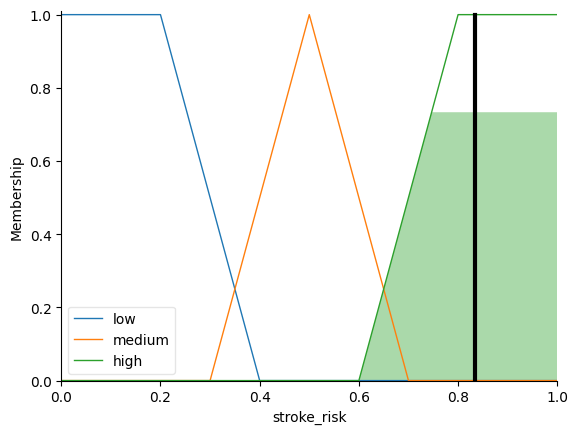

In [7]:
stroke_sim.input["age"] = 70
stroke_sim.input["glucose"] = 180
stroke_sim.input["bmi"] = 35

stroke_sim.compute()

stroke_sim.print_state()

print(f"Рассчитанный уровень риска инсульта: {stroke_sim.output['stroke_risk']:.2f}")

stroke_risk.view(sim=stroke_sim)

              precision    recall  f1-score   support

   No Stroke       0.96      0.74      0.84       960
      Stroke       0.11      0.47      0.17        62

    accuracy                           0.73      1022
   macro avg       0.53      0.61      0.50      1022
weighted avg       0.90      0.73      0.80      1022



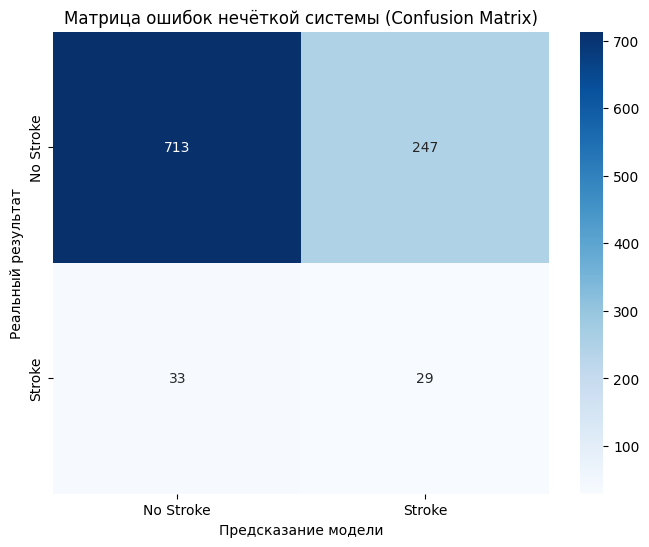

In [8]:
def evaluate_fuzzy_system(X: pd.DataFrame, simulation: ctrl.ControlSystemSimulation) -> list:
    predictions = []
    
    for _, row in X.iterrows():
        simulation.input["age"] = row["age"]
        simulation.input["glucose"] = row["avg_glucose_level"]
        simulation.input["bmi"] = row["bmi"]
        
        try:
            simulation.compute()
            score = simulation.output["stroke_risk"]
            predictions.append(1 if score > 0.5 else 0)
        except:
            predictions.append(0)
    
    return predictions


f_y_pred = evaluate_fuzzy_system(X_test, stroke_sim)
print(classification_report(y_test, f_y_pred, target_names=["No Stroke", "Stroke"]))

cm = confusion_matrix(y_test, f_y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Stroke", "Stroke"],
    yticklabels=["No Stroke", "Stroke"],
)

plt.xlabel("Предсказание модели")
plt.ylabel("Реальный результат")
plt.title("Матрица ошибок нечёткой системы (Confusion Matrix)")
plt.show()